# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Boyko Roman'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 4      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 4, файл lr6_варіант_04.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: бо в нас прогноз категорії, розірве клієнт договір чи ні

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: бо звичайна точність скаже, що ніхто не прийме договір, а наш варіант якраз для незбалансованих класів

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація потрібна щоб у кожній згортцйі даних частка кожного класу була така сама, як у всій вибірці

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.273

типи стовпців: {'str': 13, 'float64': 8, 'int64': 5}


In [6]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.

info_table = pd.DataFrame({
    "тип": raw.dtypes,
    "унікальних": raw.nunique(),
    "% пропусків": raw.isna().mean() * 100,
    "приклад": raw.apply(lambda x: x.dropna().iloc[0] if x.notna().any() else None),
}).reset_index().rename(columns={"index": "стовпець"})

info_table = info_table.sort_values("% пропусків", ascending=False)
display(info_table)

,стовпець,тип,унікальних,% пропусків,приклад
23,код_причини_закриття,str,5,72.750000,ПЕР-01
22,сума_повернення_депозиту,float64,325,72.750000,304.26
17,середній_час_відповіді_хв,float64,265,33.333333,1.0
14,трафік_ГБ,str,962,5.000000,50.9
12,щомісячний_платіж,str,1127,4.000000,315.85
16,аварій_на_ділянці_за_квартал,float64,5,3.000000,0.0
2,стать,str,6,0.000000,ж
3,місто,str,6,0.000000,Львів
0,id_клієнта,str,1200,0.000000,K40000
1,вік,float64,62,0.000000,41.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
bad_traffic = raw[pd.to_numeric(raw["трафік_ГБ"], errors="coerce").isna()]
print(bad_traffic["трафік_ГБ"].dropna().head())
print()
bad_m_payment = raw[pd.to_numeric(raw["щомісячний_платіж"], errors="coerce").isna()]
print(bad_m_payment["щомісячний_платіж"].dropna().head())


677    1900-01-06 00:00:00
906    1900-01-11 00:00:00
922    1900-01-27 00:00:00
Name: трафік_ГБ, dtype: str

155    205.49 грн
183    199.39 грн
205    208.14 грн
277    263.93 грн
279    235.74 грн
Name: щомісячний_платіж, dtype: str


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'клієнт жодного разу не звертався у підтримку'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # ----- ВАШ КОД -----
        # 1) None / NaN            -> np.nan
        if pd.isna(v):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, pd.Timestamp)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        if isinstance(v, str):
            v_clean = v.replace(',','.')
            m = re.search(r'[-+]?\d*\.?\d+', v_clean)
            if m:
                try:
                    return float(m.group())
                except ValueError:
                    return np.nan
        return np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        # ----- ВАШ КОД -----
        # дата_підключення -> число (день);
        # текстова колонка, де >80% значень розбираються в число -> число;
        # інша текстова -> category (не забудьте привести регістр і пробіли);
        # числова -> float
        if c == "дата_підключення":
            X[c]= pd.to_datetime(d[c], errors="coerce").apply(
                lambda x:x.toordinal() if pd.notna(x) else np.nan
            )
            log.append({"column": c, "action": "date -> number (days)"})
        elif pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            log.append({"column": c, "action": "number -> float"})
        else:
            num_s = to_number(d[c])
            if num_s.count() / max(1, d[c].count()) > 0.8:
                X[c] = num_s
                log.append({"column": c, "action": "text -> number"})
            else:
                X[c] = (d[c].astype(str)
                    .str.lower()
                    .str.replace(r'\s+', '', regex=True)
                    .astype("category")
                )
                log.append({"column": c, "action": "text -> category"})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 6


,column,action
0,вік,number -> float
1,стать,text -> category
2,місто,text -> category
3,філія,text -> number
4,тариф,text -> category
5,тип_підключення,text -> category
6,спосіб_оплати,text -> category
7,автоплатіж,text -> category
8,кількість_послуг,number -> float
9,місяців_обслуговування,number -> float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    # ----- ВАШ КОД -----
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    num_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
    )
    cat_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown='ignore'))
    ]
    )
    preprocessor = ColumnTransformer(transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
    )
    
    return Pipeline(steps=[
        ('prep', preprocessor),
        ('clf', clf)   
    ])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.974


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.973 ± 0.008
час      : 0.9 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = 'Це число - 0.973 є дуже високим, тобто майже ідеальним, а такого бути не може, отже спрацював витік даних'
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

Це число - 0.973 є дуже високим, тобто майже ідеальним, а такого бути не може, отже спрацював витік даних


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        # ----- ВАШ КОД -----
        # підказка: показник = roc_auc_score(y, d[c].notna().astype(int)),
        # але рахувати його можна лише якщо обидві групи більші за min_group
        is_filled = d[c].notna().astype(int)
        filled_count = is_filled.sum()
        not_filled_count = len(is_filled)-filled_count
        if filled_count > min_group and not_filled_count > min_group:
            score = roc_auc_score(y, d[c].notna().astype(int))
            if score < 0.5:
                score = 1.0 - score
            churn_if_filled = y[is_filled == 1].mean()
            churn_if_missing = y[is_filled == 0].mean()

            rows.append({
                'ознака': c,
                'заповнено': filled_count,
                'частка_відтоку_де_заповнено': churn_if_filled,
                'частка_відтоку_де_пропуск': churn_if_missing,
                'показник': score,
            })

    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,сума_повернення_депозиту,327,1.000000,0.000000,1.000000
5,код_причини_закриття,327,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,800,0.312500,0.192500,0.567257
1,трафік_ГБ,1140,0.273684,0.250000,0.502837
0,щомісячний_платіж,1152,0.271701,0.291667,0.501934
2,аварій_на_ділянці_за_квартал,1164,0.273196,0.250000,0.501702


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    # 'назва_стовпця',   # чому його немає в момент прогнозу
    "сума_повернення_депозиту", # Депозит повертають клієнту лише після того, як договір уже розірвано
    "код_причини_закриття",  # Причину закриття вносять у базу лише з відходу клієнта.
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['сума_повернення_депозиту', 'код_причини_закриття']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.973 ± 0.007


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = [
    # 'назва_стовпця',   # Заповнюється менеджером відділу під час або після розмови з клієнтом.
    "оцінка_ризику_менеджером"
]
HUMAN_LEAK_WHY = 'Детектор із 5.1 шукав витік лише за фактом наявності чи відсутності значення. Оскільки ця колонка заповнена для всіх клієнтів на 100%, сам факт її заповненості нічого не видає.'      # чому детектор із 5.1 його не спіймав

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.845 ± 0.027


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

--- ВІДТІК ЗА ФІЛІЯМИ ---
філія
Ф-01 Центр        0.393519
Ф-02 Захід        0.325000
Ф-05 Північ       0.261538
Ф-04 Південь      0.241026
Ф-03 Схід         0.227513
Ф-06 Приміська    0.175610
Name: відтік, dtype: float64

--- ВІДТІК ЗА МІСЯЦЕМ ПІДКЛЮЧЕННЯ ---
дата_підключення
2023-01    0.311475
2023-02    0.292683
2023-03    0.261905
2023-04    0.327273
2023-05    0.264706
2023-06    0.315789
2023-07    0.281250
2023-08    0.272727
2023-09    0.338462
2023-10    0.216667
2023-11    0.250000
2023-12    0.224138
2024-01    0.350000
2024-02    0.227273
2024-03    0.219512
2024-04    0.260000
2024-05    0.272727
2024-06    0.275000
2024-07    0.333333
2024-08    0.354839
2024-09    0.244444
2024-10    0.250000
2024-11    0.184211
2024-12    0.166667
Name: відтік, dtype: float64


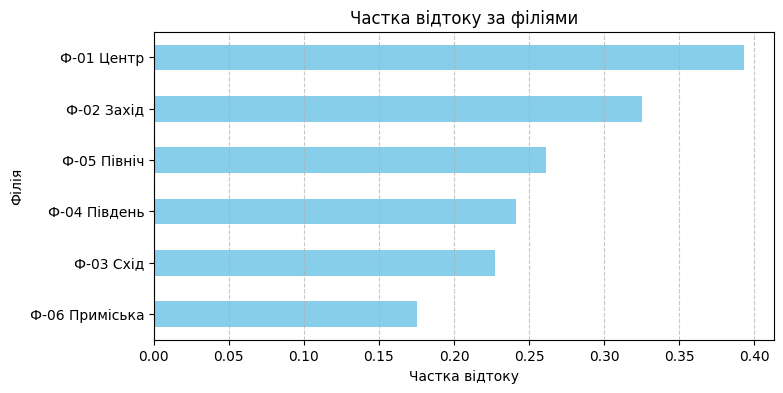

In [19]:
# ----- ВАШ КОД -----
# 1) Частка відтоку за кожною філією
print("--- ВІДТІК ЗА ФІЛІЯМИ ---")
print(raw.groupby('філія')[TARGET].mean().sort_values(ascending=False))

# 2) Частка відтоку за періодом
print("\n--- ВІДТІК ЗА МІСЯЦЕМ ПІДКЛЮЧЕННЯ ---")
період = raw['дата_підключення'].astype(str).str[:7] 
print(raw.groupby(період)[TARGET].mean())

branch_churn = raw.groupby('філія')[TARGET].mean().sort_values(ascending=True)

branch_churn.plot(kind='barh', color='skyblue', figsize=(8, 4))
plt.title('Частка відтоку за філіями')
plt.xlabel('Частка відтоку')
plt.ylabel('Філія')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія'          : 1 для філій із різко іншою часткою відтоку
# для 'дата_підключення': 1 для клієнтів, підключених після дати-зламу
source = (raw["філія"]== "Ф-01 Центр").astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.625
ті самі ознаки передбачають ВІДТІК  : AUC 0.834 ± 0.028


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.973
2. мінус цільовий витік,22,0.973
3. мінус оцінки людини,21,0.845
4. мінус артефакт збору,20,0.834


чесне число: 0.834 ± 0.028


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = 'Оскільки AUC передбачення джерела > 0.5, філія несе в собі специфіку конкретного відділення. Якщо її залишити, модель може погано працювати в інших філіях.'
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — Оскільки AUC передбачення джерела > 0.5, філія несе в собі специфіку конкретного відділення. Якщо її залишити, модель може погано працювати в інших філіях.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
from sklearn.tree import DecisionTreeClassifier
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=3, random_state=SEED),   # ----- ВАШ КОД -----
    'випадковий ліс':       RandomForestClassifier(n_jobs=-1, random_state=SEED),   # ----- ВАШ КОД -----
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),   # ----- ВАШ КОД -----
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.834,0.028,0.8
одне дерево,0.712,0.029,0.7
випадковий ліс,0.825,0.026,4.8
гістограмний бустинг,0.824,0.028,8.9


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    # ----- ВАШ КОД -----
    diff = b-a
    n = len(diff)
    m = diff.mean()

    h = 1.96 * diff.std(ddof=1) / np.sqrt(n)
    return m, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0087 ± 0.0091   у межах шуму
гістограмний бустинг   проти логістичної: -0.0097 ± 0.0101   у межах шуму


In [25]:
CHOSEN_MODEL = 'логістична регресія'     # назва з MODELS
CHOSEN_WHY = 'Інші моделі не показали покращення результату. Отже, ми обираємо логістичну регресію як найшвидшу, найпростішу та найбільш зрозумілу модель.'       # за якими з чотирьох критеріїв і чому саме так
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — Інші моделі не показали покращення результату. Отже, ми обираємо логістичну регресію як найшвидшу, найпростішу та найбільш зрозумілу модель.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # ----- ВАШ КОД: щонайменше три ознаки, кожна з коментарем-гіпотезою -----
    F['ціна_за_Мбіт'] = F['щомісячний_платіж'] / (F['швидкість_тарифу_Мбіт'] + 1e-9)
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1e-9)
    F['має_знижку'] = (F['знижка_відсоток'] > 0).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [27]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.833 ± 0.029
приріст проти базового набору: -0.0011 ± 0.0018   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
FEATURES_VS_MODEL = 'Обидва шляхи не дали покращення результату. Але складні моделі вимагали більше часу на навчання, тоді як додавання ознак майже не уповільнило логістичну регресію. Жоден метод майже не підвищив якість, тому логістична регресія залишається найкращою.'
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Обидва шляхи не дали покращення результату. Але складні моделі вимагали більше часу на навчання, тоді як додавання ознак майже не уповільнило логістичну регресію. Жоден метод майже не підвищив якість, тому логістична регресія залишається найкращою.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.804
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

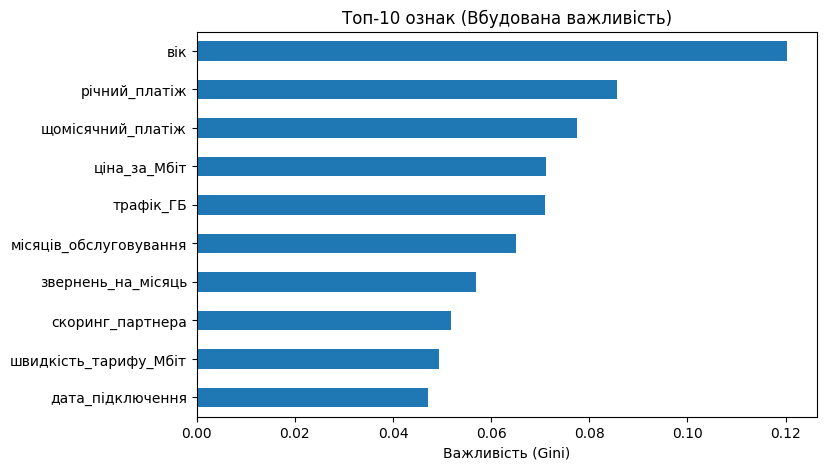

In [30]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
out_cols = model.named_steps['prep'].get_feature_names_out()
importances = model.named_steps['clf'].feature_importances_
# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
imp_dict = {c: 0.0 for c in FINAL_X.columns}
for col, imp in zip(out_cols, importances):
    col_name = col.split("__", 1)[-1]
    for orig_c in FINAL_X.columns:
        if col_name == orig_c or col_name.startswith(orig_c + '_'):
            imp_dict[orig_c] += imp
            break
gini_imp = pd.Series(imp_dict).sort_values(ascending=False)
# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
gini_imp.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
import matplotlib.pyplot as plt
plt.title('Топ-10 ознак (Вбудована важливість)')
plt.xlabel('Важливість (Gini)')
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.080873
місяців_обслуговування,0.040026
звернень_на_місяць,0.016959
трафік_ГБ,0.016907
річний_платіж,0.013335
швидкість_тарифу_Мбіт,0.009043
щомісячний_платіж,0.008444
автоплатіж,0.007612
аварій_на_ділянці_за_квартал,0.003799
номер_договору_серія,0.003492


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
comp_table = pd.DataFrame(
    {
        "вбудована": gini_imp,
        "перестановочна": perm_imp,
    }
).sort_values("вбудована", ascending = False)
display(comp_table.head(10))

,вбудована,перестановочна
вік,0.120341,0.080873
річний_платіж,0.085668,0.013335
щомісячний_платіж,0.077463,0.008444
ціна_за_Мбіт,0.071113,-0.000234
трафік_ГБ,0.071005,0.016907
місяців_обслуговування,0.064970,0.040026
звернень_на_місяць,0.056984,0.016959
скоринг_партнера,0.051890,-0.001447
швидкість_тарифу_Мбіт,0.049433,0.009043
дата_підключення,0.047214,-0.001410


In [33]:
FAKE_IMPORTANT = 'ціна_за_Мбіт'        # назва ознаки
FAKE_IMPORTANT_WHY = 'Ця ознака є неперервною величиною з великою кількістю унікальних значень. Дерево перебирає їх усі і завжди знаходить випадковий поріг, який трохи зменшує неоднорідність на навчальних даних, тому сильно завищує її важливість.'    # чому вбудована важливість її переоцінює
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: ціна_за_Мбіт


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
corr_matrix = FINAL_X.select_dtypes(include='number').corr()

print("Пари ознак із кореляцією |r| > 0.97:")
for col1 in corr_matrix.columns:
    for col2 in corr_matrix.columns:
        if col1 < col2 and abs(corr_matrix.loc[col1, col2]) > 0.97:
            print(f"'{col1}' та '{col2}': {corr_matrix.loc[col1, col2]:.4f}")

Пари ознак із кореляцією |r| > 0.97:
'річний_платіж' та 'щомісячний_платіж': 0.9993


In [35]:
from sklearn.base import clone
DUP_PAIR = ['річний_платіж', 'щомісячний_платіж']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
new_X = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_new, Xte_new, ytr_new, yte_new = train_test_split(new_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model_new = make_pipe(new_X, clone(FINAL_CLF)).fit(Xtr_new, ytr_new)

perm_new = permutation_importance(model_new, Xte_new, yte_new, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_new = pd.Series(perm_new.importances_mean, index=new_X.columns)

print('\nбез пари:')
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_imp_new[DUP_PAIR[0]]))

у повній моделі:
   річний_платіж                +0.0133
   щомісячний_платіж            +0.0084

без пари:
   річний_платіж                +0.0285


In [36]:
DUP_EXPLANATION = 'Коли в моделі є дві дубльовані ознаки, перемішування однієї з них майже не погіршує якість прогнозу, бо модель може побачити ту саму інформацію в іншій колонці. Але якщо прибрати одну з них, важливість тієї, що залишилася, різко зростає, оскільки тепер модель повністю покладається лише на неї.'
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Коли в моделі є дві дубльовані ознаки, перемішування однієї з них майже не погіршує якість прогнозу, бо модель може побачити ту саму інформацію в іншій колонці. Але якщо прибрати одну з них, важливість тієї, що залишилася, різко зростає, оскільки тепер модель повністю покладається лише на неї.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

Топ-3 числові ознаки для PDP: ['вік', 'місяців_обслуговування', 'звернень_на_місяць']


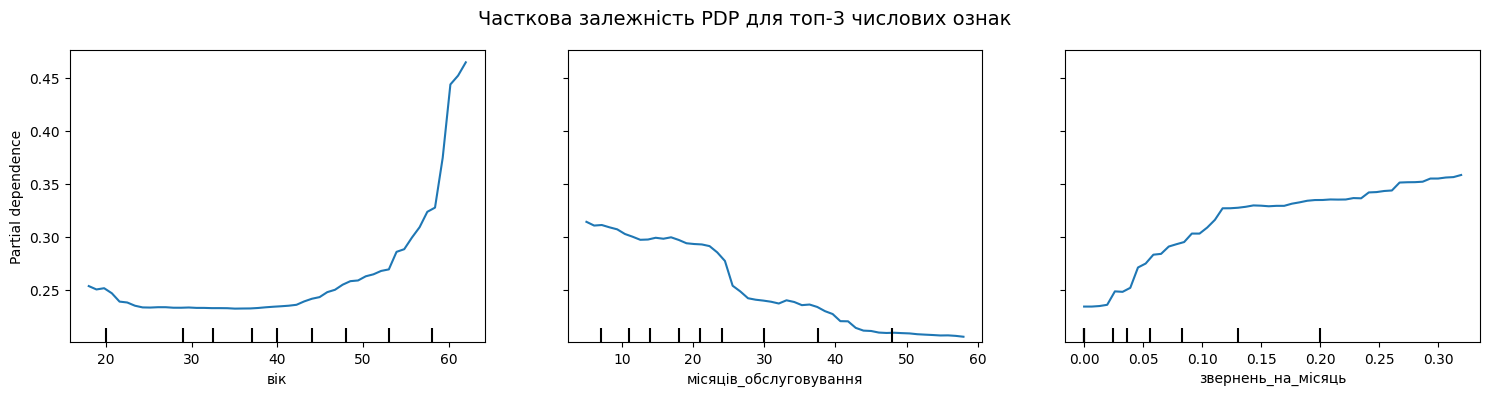

In [37]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
# PartialDependenceDisplay.from_estimator(model, Xte, features=[...], kind='average')
# Увага: ознака з пропусками дасть порожню сітку — беріть ознаки без NaN
# або будуйте PDP на підвибірці, де ця ознака заповнена.
num_cols = FINAL_X.select_dtypes(include='number').columns
top_3_num = perm_imp[perm_imp.index.isin(num_cols)].head(3).index.tolist()

print(f"Топ-3 числові ознаки для PDP: {top_3_num}")
fig, ax = plt.subplots(figsize=(15, 4))

PartialDependenceDisplay.from_estimator(
    model,
    Xte,
    features=top_3_num,
    kind='average',
    grid_resolution=50,
    ax=ax
)
plt.suptitle('Часткова залежність PDP для топ-3 числових ознак', fontsize=14)
plt.tight_layout()
plt.show()

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

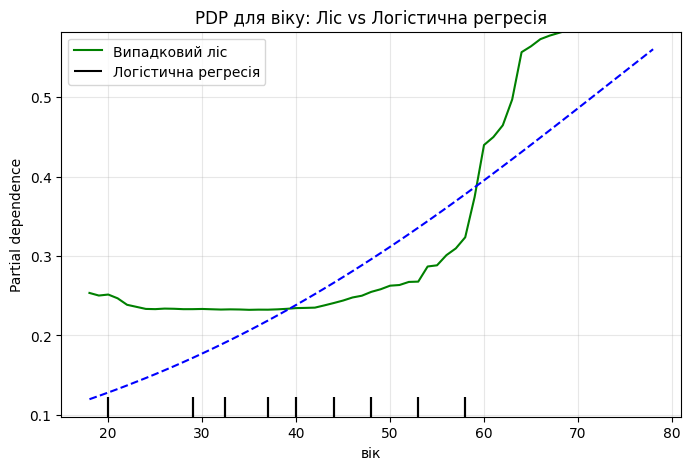

In [38]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
fig, ax = plt.subplots(figsize=(8, 5))
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

disp1 = PartialDependenceDisplay.from_estimator(
    model, Xte, [NONLINEAR_FEATURE], ax=ax, line_kw={'color': 'green', 'label': 'Випадковий ліс'}
)

# Малюємо криву для логістичної регресії, вказуючи осі з disp1
PartialDependenceDisplay.from_estimator(
    model_lr, Xte, [NONLINEAR_FEATURE], ax=disp1.axes_, line_kw={'color': 'blue', 'linestyle': '--', 'label': 'Логістична регресія'}
)

plt.title('PDP для віку: Ліс vs Логістична регресія')
plt.legend(['Випадковий ліс', 'Логістична регресія'])
plt.grid(alpha=0.3)
plt.show()

In [39]:
NONLINEAR_MEANING = 'Клієнти середнього віку - близько 35 років, є найбільш лояльними та стабільними, ризик відтоку там мінімальний. Проте молодь - до 25, і особливо клієнти старшого віку - 50+, розривають договори значно частіше.'     # що означає ця форма змістовно, мовою предметної області
NONLINEAR_FIX = 'Треба зробити нову квадратичну ознаку — квадрат відхилення віку від точки мінімуму ризику.'         # яку ознаку треба сконструювати, щоб лінійна модель це побачила
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Клієнти середнього віку - близько 35 років, є найбільш лояльними та стабільними, ризик відтоку там мінімальний. Проте молодь - до 25, і особливо клієнти старшого віку - 50+, розривають договори значно частіше.
Треба зробити нову квадратичну ознаку — квадрат відхилення віку від точки мінімуму ризику.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
OPT_AGE = 35
# 2) додайте ознаку «квадрат відхилення від цього значення»;
X_quad = FINAL_X.copy()
X_quad['вік_відхилення_кв'] = (X_quad['вік'] - OPT_AGE) ** 2
# 3) парне порівняння логістичної регресії з нею і без неї.
base_lr = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
base_quad = cross_val_score(make_pipe(X_quad, logreg()), X_quad, y, cv=cv, scoring='roc_auc')
m_quad, h_quad = paired(base_lr, base_quad)
print('AUC базової регресії: %.3f' % base_lr.mean())
print('AUC з новою ознакою:  %.3f' % base_quad.mean())
print('приріст від квадрату: %+0.4f ± %.4f   %s' 
      % (m_quad, h_quad, 'значуще' if abs(m_quad) > h_quad else 'у межах шуму'))

AUC базової регресії: 0.833
AUC з новою ознакою:  0.853
приріст від квадрату: +0.0200 ± 0.0053   значуще


In [41]:
QUAD_GAIN = float(m_quad)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0200


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

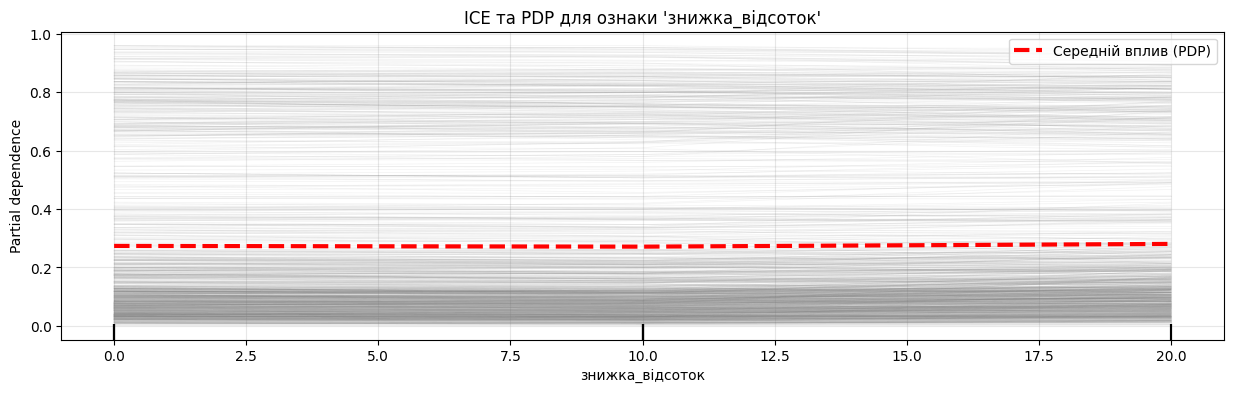

In [42]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, ax = plt.subplots(figsize=(15, 4))

PartialDependenceDisplay.from_estimator(
    model,
    FINAL_X,
    features=['знижка_відсоток'],
    kind='both',
    grid_resolution=50,
    ax=ax,
    pd_line_kw={'color': 'red', 'linewidth': 3, 'label': 'Середній вплив (PDP)'},
    ice_lines_kw={'color': 'gray', 'alpha': 0.1, 'linewidth': 0.5}
)

plt.title("ICE та PDP для ознаки 'знижка_відсоток'")
plt.grid(alpha=0.3)
plt.show()

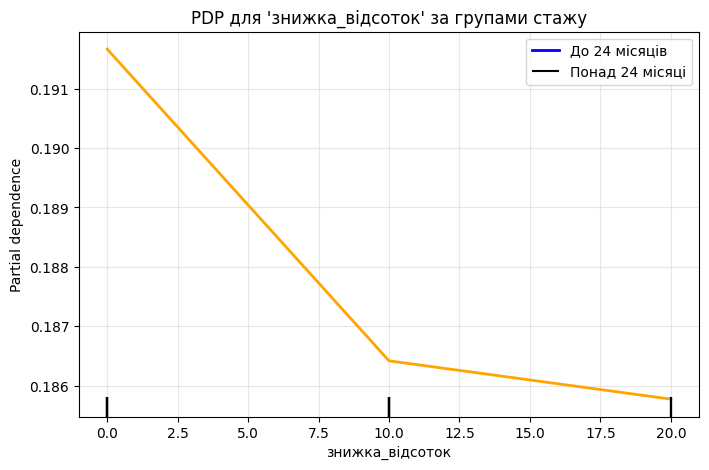

In [43]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
exp_new = FINAL_X['місяців_обслуговування'] <= 24
exp_old = FINAL_X['місяців_обслуговування'] > 24

fig, ax = plt.subplots(figsize=(8, 5))

disp_new = PartialDependenceDisplay.from_estimator(
    model, FINAL_X[exp_new], ['знижка_відсоток'], 
    kind='average', ax=ax, line_kw={'color': 'blue', 'linewidth': 2}
)

PartialDependenceDisplay.from_estimator(
    model, FINAL_X[exp_old], ['знижка_відсоток'], 
    kind='average', ax=disp_new.axes_, line_kw={'color': 'orange', 'linewidth': 2}
)

plt.title("PDP для 'знижка_відсоток' за групами стажу")
plt.legend(['До 24 місяців', 'Понад 24 місяці'])
plt.grid(alpha=0.3)
plt.show()

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
raw_check = raw.copy()
raw_check['група_стажу'] = np.where(raw_check['місяців_обслуговування'] <= 24, '1. До 24 місяців', '2. Понад 24 місяці')

pivot = raw_check.groupby(['група_стажу', 'знижка_відсоток'])[TARGET].agg(['mean', 'count'])
display(pivot)

mean  count
група_стажу        знижка_відсоток                 
1. До 24 місяців   0                0.323529    306
                   10               0.331797    217
                   20               0.433673    196
2. Понад 24 місяці 0                0.253012    166
                   10               0.128342    187
                   20               0.039062    128

In [45]:
INTERACTION_FOUND = 'Для клієнтів "до 24 місяців" збільшення знижки супроводжується ЗРОСТАННЯМ частки відтоку. Проте для клієнтів "понад 24 місяці" знижка працює краще: чим вона більша, тим МЕНШИЙ ризик відтоку.'     # опишіть, що робить знижка в кожній із двох груп
BUSINESS_ACTION = 'Відділу утримання варто пропонувати знижки насамперед клієнтам "понад 24 місяці", оскільки там цей інструмент ефективно утримує людей. Для нових клієнтів знижка не працює, тому для них треба шукати інші методи утримання.'       # що з цього випливає для відділу утримання
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Для клієнтів "до 24 місяців" збільшення знижки супроводжується ЗРОСТАННЯМ частки відтоку. Проте для клієнтів "понад 24 місяці" знижка працює краще: чим вона більша, тим МЕНШИЙ ризик відтоку.
Відділу утримання варто пропонувати знижки насамперед клієнтам "понад 24 місяці", оскільки там цей інструмент ефективно утримує людей. Для нових клієнтів знижка не працює, тому для них треба шукати інші методи утримання.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 39)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

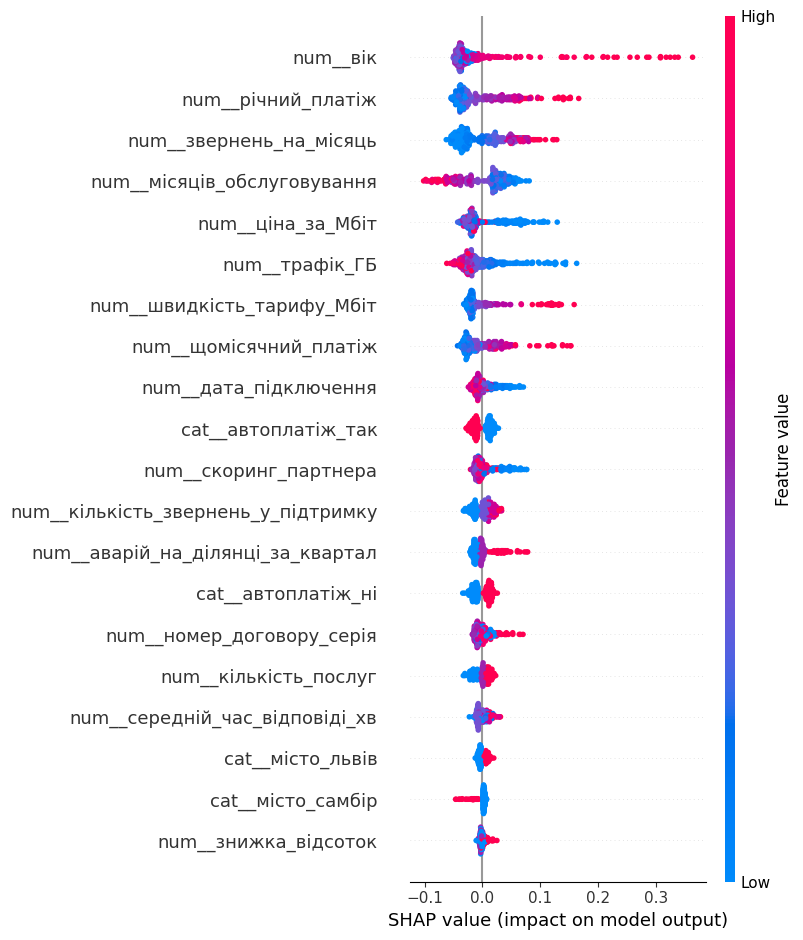

In [47]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
plt.figure(figsize=(10, 6))

shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
client_shap = sv1[idx]
client_sv = pd.Series(client_shap, index=feat_names)

top_3 = client_sv.abs().sort_values(ascending=False).head(3)

print("\nТоп-3 ознаки, що вплинули на прогноз:")
for feat in top_3.index:
    print(f"{feat}: {client_sv[feat]:.4f}")

ризик клієнта: 0.877

Топ-3 ознаки, що вплинули на прогноз:
num__швидкість_тарифу_Мбіт: 0.1328
num__річний_платіж: 0.1315
num__щомісячний_платіж: 0.1237


In [49]:
EXPLANATION_FOR_MANAGER = 'Цей клієнт має дуже високий ризик розірвання договору. 1. він має невідповідну швидкість тарифу; 2. він сплачує дуже високий платіж; 3. співвідношення ціни до швидкості для нього є невигідним.'
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цей клієнт має дуже високий ризик розірвання договору. 1. він має невідповідну швидкість тарифу; 2. він сплачує дуже високий платіж; 3. співвідношення ціни до швидкості для нього є невигідним.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = 'Значення Шеплі показують, що старший вік сильно збільшує ризик відтоку. Проте ми не можемо змінити вік клієнта. Значення Шеплі показує те, як модель використовує дані для передбачення.'
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — Значення Шеплі показують, що старший вік сильно збільшує ризик відтоку. Проте ми не можемо змінити вік клієнта. Значення Шеплі показує те, як модель використовує дані для передбачення.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",ціна_за_Мбіт,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",річний_платіж + щомісячний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = 'Ознака "філія" або "дата підключення" може мати високу важливість. Насправді це артефакт збору даних: в той період або в тій філії діяла специфічна акція, на яку прийшли нелояльні клієнти, тому відтік там вищий суто через спосіб залучення, а не через якість роботи відділення.'
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Ознака "філія" або "дата підключення" може мати високу важливість. Насправді це артефакт збору даних: в той період або в тій філії діяла специфічна акція, на яку прийшли нелояльні клієнти, тому відтік там вищий суто через спосіб залучення, а не через якість роботи відділення.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100

probs = model.predict_proba(Xte)[:, 1]

results_df = pd.DataFrame({'real_churn': yte, 'prob': probs})

top_100 = results_df.sort_values(by='prob', ascending=False).head(TOP_N)

lift = top_100['real_churn'].mean() / yte.mean()

print(f"Lift для топ-{TOP_N}: {lift:.3f}")

Lift для топ-100: 2.204


In [54]:
LIFT_MEANING = 'Метрика Lift 2.204 показує, що обдзвін цих 100 обраних моделлю клієнтів у 2.2 раза ефективніший за обдзвін навмання.'    # що число lift означає для бізнесу, одним реченням
assert LIFT_MEANING
print(LIFT_MEANING)

Метрика Lift 2.204 показує, що обдзвін цих 100 обраних моделлю клієнтів у 2.2 раза ефективніший за обдзвін навмання.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_04.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
REPORT = '''
1. Обрано метрику AUC, оскільки класи незбалансовані - частка відтоку 27.3%. На таких даних наївна модель "ніхто не піде" дала б точність 72.7%, що робить звичайну точність марною.
2. Викинено: `id_клієнта`: не несе змісту, `сума_повернення_депозиту` та `код_причини_закриття`: цільовий витік, з'являються вже після закриття договору. Детектор не спіймав `оцінка_ризику_менеджером`, бо вона заповнена на 100%.
3. Чесне число AUC: 0.834 +- 0.028. Розкид +-0.028 означає, що різниця між моделями у 0.004 знаходиться в межах шуму, тому приріст не є значущим.
4. Артефакт збору виявлено в ознаці `філія` - AUC джерела 0.625. Модель вивчає специфіку конкретних відділень, тому їй не можна повністю довіряти при перенесенні на інші філії.
5. Складніша модель не дала значущого приросту: -0.0087 ± 0.0091 і працювала значно довше: 3.6 с проти 0.5 с. Проте стаорення ознаки квадрата віку дало приріст: +0.0200 для простої лінійної моделі.
6. Вбудована важливість хибно переоцінила `ціна_за_Мбіт`. Вона стала неперервною з величезною кількістю унікальних значень, тому дерево завжди знаходить поріг, що випадково покращує розбиття на навчальних даних.
7. Перестановочна важливість дубльованої пари: `річний_платіж` і `щомісячний_платіж` була заниженою. Коли одну прибрали, важливість іншої різко зросла. Це не вада методу, адже якість не падає без однієї з колонок, бо модель бере ту саму інформацію з іншої.
8. Ознака `вік` має немонотонний вплив. Логістична регресія цього б не побачила за побудовою, доки ми не додали ознаку квадрата відхилення від оптимуму - 35 років.
9. Середній PDP збрехав на ознаці `знижка_відсоток`, показавши пласку криву. ICE і розбиття по групах стажу виявили, що для клієнтів "до 24 місяців" ризик від знижки зростає, а для клієнтів "понад 24 міс" ризик спадає.
10. Великий внесок за Шеплі має `вік`, але ми не можемо його змінити, щоб утримати клієнта. Значення Шеплі показують, як модель використовує дані.
11. Для 100 дзвінків ефективність буде в 2.2 раза вищою за випадкову: Lift = 2.204. Застереження: високий передбачений ризик відтоку означає намір піти, але дзвінок зі знижкою не гарантує, що клієнт передумає.

Декларація про використання ШІ:
Використовував ШІ-асистента для допомоги з написанням коду обробки даних: додавання ознак, зведені таблиці, матриця кореляцій, побудова графіків PDP та ICE.
'''
print(REPORT)


1. Обрано метрику AUC, оскільки класи незбалансовані - частка відтоку 27.3%. На таких даних наївна модель "ніхто не піде" дала б точність 72.7%, що робить звичайну точність марною.
2. Викинено: `id_клієнта`: не несе змісту, `сума_повернення_депозиту` та `код_причини_закриття`: цільовий витік, з'являються вже після закриття договору. Детектор не спіймав `оцінка_ризику_менеджером`, бо вона заповнена на 100%.
3. Чесне число AUC: 0.834 +- 0.028. Розкид +-0.028 означає, що різниця між моделями у 0.004 знаходиться в межах шуму, тому приріст не є значущим.
4. Артефакт збору виявлено в ознаці `філія` - AUC джерела 0.625. Модель вивчає специфіку конкретних відділень, тому їй не можна повністю довіряти при перенесенні на інші філії.
5. Складніша модель не дала значущого приросту: -0.0087 ± 0.0091 і працювала значно довше: 3.6 с проти 0.5 с. Проте стаорення ознаки квадрата віку дало приріст: +0.0200 для простої лінійної моделі.
6. Вбудована важливість хибно переоцінила `ціна_за_Мбіт`. Вона стала

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.